# Module 12 Guided Lab: Introduction to Predictive Modeling with Linear Regression

**BAN 6003: Data Management and Analytics Integration**

In the previous module, we checked and documented an ABT. Now we begin applying analytics to an ABT.

This module introduces supervised predictive modeling through a linear regression workflow.

The main idea is:

> Use known variables, called features, to predict a continuous outcome, called the target.

For this lab, we will use the `nycflights13` data to predict **arrival delay in minutes**.

## Lab Learning Goals

By the end of this lab, you should be able to:

1. Explain the purpose of supervised predictive modeling.
2. Distinguish features and target variables.
3. Split data into training and testing sets.
4. Fit a linear regression model using Scikit-learn.
5. Generate predictions.
6. Calculate MAE, RMSE, and R-squared, and compare them with a simple baseline.
7. Interpret coefficients cautiously, paying attention to units.
8. Explain why the time of the prediction decides which features you may use (data leakage).
9. Apply the same workflow to a second business problem and turn coefficients into business insight.

This is an introductory modeling lab. The goal is not to build the perfect model. The goal is to understand the workflow and to judge honestly what a model can and cannot do.

## Business Scenario

An airline operations team wants to estimate how late each flight will arrive.

The key question in this lab is:

> **What you can predict depends on WHEN you predict.**

We will build two models for two different decision times:

| Model | Decision time | Business use | Features |
|---|---|---|---|
| **Model A** | The evening before the flight | Plan staff and gates for tomorrow | Schedule, route, airline, weather at the scheduled hour, plane age |
| **Model B** | At departure (the plane has just left the gate) | Update the arrival estimate for passengers and the arrival airport | Everything in Model A **plus** the actual departure delay |

- **Target variable:** `arr_delay` (arrival delay in minutes)
- **One row:** one flight

We will also compare both models with a **baseline**: a "model" that predicts the same average delay for every flight. A useful model must beat this baseline.

## 0. Setup

We will use:

- `pandas` and `numpy` for data handling
- `matplotlib` for basic visualization
- `scikit-learn` for modeling
- `nycflights13` for data

### Package setup note

You can work in GitHub Codespaces or in local VS Code. On the UTSA campus network Codespaces may not connect; use the local setup there (see the Canvas page on local setup).

In **GitHub Codespaces**, the required packages are already installed. You do not need to run any `%pip install` command.

On your **local computer**, if an import fails, uncomment and run the `%pip install` line(s) in the setup cell below, then rerun the imports.

In [9]:
# Codespaces: nycflights13 and scikit-learn are already installed.
# Local only: if the imports below fail, uncomment and run the needed line(s):
# %pip install nycflights13 "setuptools<81"
# (setuptools<81 is needed because nycflights13 uses pkg_resources, which newer setuptools removed.)
# %pip install -q scikit-learn

import nycflights13
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Find the repository folder (works from the repo root or from notebooks/)
repo_root = Path.cwd()
if not (repo_root / "README.md").exists() and (repo_root.parent / "README.md").exists():
    repo_root = repo_root.parent

# Folder where the lab saves its CSV files
output_dir = repo_root / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

## 1. Build the Flight ABT

We build a flight-level ABT from three `nycflights13` tables. One row represents one flight.

1. **`flights`**: schedule, airline (`carrier`), airport (`origin`), `distance`, delays. We keep only flights with a known departure delay and arrival delay. Cancelled and diverted flights have no arrival delay, so they cannot be used to train a model of arrival delay.
2. **`weather`**: hourly weather at each New York airport. We join the weather at the **origin airport in the scheduled departure hour** (`hour` in `flights` is the scheduled departure hour). A few weather hours appear twice, so we remove duplicate keys first; otherwise the join would copy some flights.
3. **`planes`**: the year each plane was built. We compute `plane_age = 2013 - plane_year`.

We also add the day of the week.

In [10]:
flights = nycflights13.flights
weather = nycflights13.weather
planes = nycflights13.planes

# Flights with a known departure delay and arrival delay
flight_rows = flights.dropna(subset=["dep_delay", "arr_delay"]).copy()

# One weather row per airport and hour (remove duplicate keys before joining)
weather_keys = ["origin", "year", "month", "day", "hour"]
weather_hourly = weather.drop_duplicates(subset=weather_keys)
weather_hourly = weather_hourly[weather_keys + ["precip", "visib", "wind_speed", "temp"]]

# The year each plane was built
plane_info = planes[["tailnum", "year"]].rename(columns={"year": "plane_year"})

# Add weather and plane year to each flight (left joins keep every flight)
flight_abt = (
    flight_rows
    .merge(weather_hourly, on=weather_keys, how="left")
    .merge(plane_info, on="tailnum", how="left")
)
# Plane age in years and the weekday name of each flight
flight_abt["plane_age"] = 2013 - flight_abt["plane_year"]
flight_abt["day_of_week"] = pd.to_datetime(flight_abt[["year", "month", "day"]]).dt.day_name()

print("Flights with known delays:", len(flight_rows))
print("Rows in the ABT:          ", len(flight_abt))

Flights with known delays: 327346
Rows in the ABT:           327346


The two row counts are the same, so the joins did not copy or lose any flights.

### Work with a reproducible sample

The full ABT has more than 300,000 flights. To keep every cell fast in Codespaces, we use a random sample of **60,000 flights**. `random_state=42` makes the sample the same for everyone, so your numbers will match your classmates' numbers.

In [11]:
# Columns we keep for modeling
columns = [
    "month", "day_of_week", "hour", "distance", "carrier", "origin",
    "precip", "visib", "wind_speed", "temp", "plane_age",
    "dep_delay", "air_time", "arr_delay"
]

# Reproducible random sample of 60,000 flights
model_data = flight_abt.sample(n=60000, random_state=42)[columns].reset_index(drop=True)

# Put the days in calendar order (Monday first)
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
model_data["day_of_week"] = pd.Categorical(model_data["day_of_week"], categories=day_order)

model_data.head()

,month,day_of_week,hour,distance,carrier,origin,precip,visib,wind_speed,temp,plane_age,dep_delay,air_time,arr_delay
0,11,Sunday,10,2475,AA,JFK,0.0,10.0,36.82496,28.04,27.0,-5.0,331.0,-23.0
1,2,Thursday,13,169,EV,EWR,0.0,10.0,5.75390,32.00,8.0,-8.0,39.0,0.0
2,5,Wednesday,19,733,UA,LGA,0.0,10.0,9.20624,57.92,5.0,-6.0,100.0,-38.0
3,7,Wednesday,8,340,9E,JFK,0.0,10.0,12.65858,80.96,13.0,-7.0,64.0,-11.0
4,9,Sunday,7,711,WN,EWR,0.0,10.0,5.75390,75.02,7.0,-5.0,106.0,-12.0


## 2. Check Missing Values

Scikit-learn's `LinearRegression` cannot use rows with missing values.

In [12]:
# Count missing values in each column
model_data.isna().sum()

month             0
day_of_week       0
hour              0
distance          0
carrier           0
origin            0
precip          267
visib           267
wind_speed      284
temp            271
plane_age      9856
dep_delay         0
air_time          0
arr_delay         0
dtype: int64

### Quick interpretation

- About 16% of flights have no `plane_age`, because their plane is not in the `planes` table.
- A few flights have no weather values, because the weather table has gaps.

Instead of dropping these rows, we will **fill each missing value with the median from the training data**. We compute the median from the training data only, because the test data must stay "unseen". This is a simple and common choice. In a real project, you should document it.

## 3. Define Target and Features

In supervised learning, we separate:

- `y`: the target variable we want to predict
- `X`: the feature variables used to make the prediction

**Text categories.** `carrier`, `origin`, and `day_of_week` are text. `month` is a number, but month 12 is not "12 times" month 1, so we also treat `month` as a **category**. `pd.get_dummies()` turns each category into 0/1 columns. With `drop_first=True`, the first category of each group (January, Monday, carrier 9E, and airport EWR) becomes the **reference category** that the other categories are compared with.

We keep the scheduled `hour` as a number, because delays tend to build up during the day.

In [13]:
target = "arr_delay"

evening_features = [
    "hour", "distance", "precip", "visib", "wind_speed", "temp", "plane_age",
    "month", "day_of_week", "carrier", "origin"
]
category_features = ["month", "day_of_week", "carrier", "origin"]

# Turn category columns into 0/1 dummy columns (drop_first drops one reference category)
X = pd.get_dummies(
    model_data[evening_features + ["dep_delay"]],
    columns=category_features,
    drop_first=True,
    dtype=int
)
y = model_data[target]

# Model A: the evening before (no departure delay yet)
evening_columns = [col for col in X.columns if col != "dep_delay"]
# Model B: at departure (Model A features + actual departure delay)
departure_columns = evening_columns + ["dep_delay"]

print("Model A uses", len(evening_columns), "columns")
print("Model B uses", len(departure_columns), "columns")
X.head()

Model A uses 41 columns
Model B uses 42 columns


,hour,distance,precip,visib,wind_speed,temp,plane_age,dep_delay,month_2,month_3,...,carrier_HA,carrier_MQ,carrier_OO,carrier_UA,carrier_US,carrier_VX,carrier_WN,carrier_YV,origin_JFK,origin_LGA
0,10,2475,0.0,10.0,36.82496,28.04,27.0,-5.0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,13,169,0.0,10.0,5.75390,32.00,8.0,-8.0,1,0,...,0,0,0,0,0,0,0,0,0,0
2,19,733,0.0,10.0,9.20624,57.92,5.0,-6.0,0,0,...,0,0,0,1,0,0,0,0,0,1
3,8,340,0.0,10.0,12.65858,80.96,13.0,-7.0,0,0,...,0,0,0,0,0,0,0,0,1,0
4,7,711,0.0,10.0,5.75390,75.02,7.0,-5.0,0,0,...,0,0,0,0,0,0,1,0,0,0


In [14]:
# Summary of the target: arrival delay in minutes
y.describe()

count    60000.000000
mean         6.953533
std         44.324800
min        -71.000000
25%        -17.000000
50%         -5.000000
75%         14.000000
max        875.000000
Name: arr_delay, dtype: float64

### Your Turn 1

In one or two sentences: What is the difference between the target and the features in this lab? Name one feature that Model B can use but Model A cannot, and explain why.

**Your answer:**
- The difference between the target, arr_delay, and the features used to predict it.
- Why model b can use dep_delay but model a can't.

## 4. Visualize a Simple Relationship

Before modeling, we look at one relationship: departure delay against arrival delay, using 2,000 flights so the plot is easy to read.

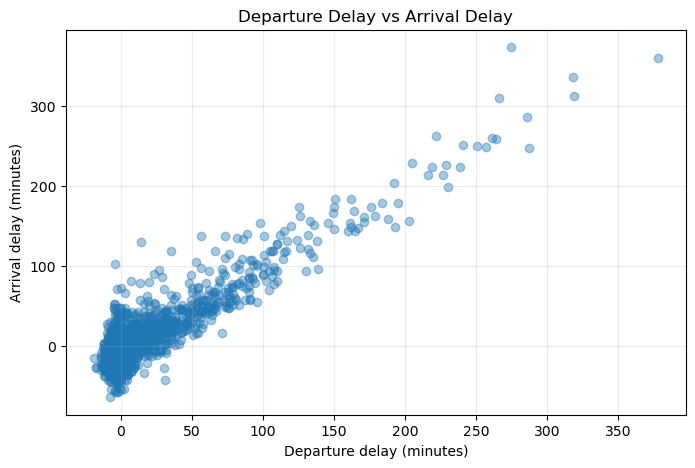

In [15]:
# 2,000 random flights keep the plot readable
plot_sample = model_data.sample(n=2000, random_state=42)

plt.figure(figsize=(8, 5))
plt.scatter(plot_sample["dep_delay"], plot_sample["arr_delay"], alpha=0.4)
plt.xlabel("Departure delay (minutes)")
plt.ylabel("Arrival delay (minutes)")
plt.title("Departure Delay vs Arrival Delay")
plt.grid(True, alpha=0.25)
plt.show()

*Plot description:* The points form a tight band that rises from the lower left to the upper right: flights that leave later almost always arrive later, by roughly the same number of minutes.

Linear regression summarizes this kind of pattern with a straight-line relationship. But departure delay is only known **at departure**. The evening before, we do not have it.

## 5. Train/Test Split

We split data into:

- **Training data (75%)**: used to fit the model and to compute the fill-in medians
- **Testing data (25%)**: used only to evaluate the model on flights it did not see

`random_state=42` makes the split reproducible.

In [17]:
# 75% training, 25% test (random_state makes the split reproducible)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)

# Fill missing values with the TRAINING median (the test data stays unseen)
fill_columns = ["precip", "visib", "wind_speed", "temp", "plane_age"]
train_medians = X_train[fill_columns].median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

X_train.shape, X_test.shape

((45000, 42), (15000, 42))

### Your Turn 2: The baseline

Before we fit any model, we need a simple point of comparison. The **baseline** predicts the **training-data average arrival delay** for every test flight.

In the empty cell below:

1. Calculate the average of `y_train`.
2. Create `my_baseline_pred`, an array that repeats this average once for every test flight. Hint: `np.full(len(y_test), value)`.
3. Calculate and print the baseline MAE with `mean_absolute_error(y_test, my_baseline_pred)`.

Check: your baseline MAE should match the "Baseline" row in the tables of Section 6 and Section 8.

In [18]:
# Your Turn 2 - your code here

basline_avg = y_train.mean()

my_baseline_pred = np.full_like(y_test, basline_avg)

basline_mae = mean_absolute_error(y_test, my_baseline_pred)

print(f"Baseline MAE: {basline_mae:.2f} minutes")

Baseline MAE: 27.95 minutes


## 6. Model A: The Evening Before

We now fit `LinearRegression` with the features that are known the evening before the flight.

**Important:** Weather in our data is the weather that was **observed** in that hour. The evening before, the airline would only have a **forecast**, which is less accurate. So Model A's results are, if anything, a little **optimistic**.

We use a small helper function so we can calculate the three metrics the same way for every model.

In [19]:
def regression_metrics(model_name, decision_time, actual, predicted):
    """Return MAE, RMSE, and R-squared for one model as a dictionary."""
    return {
        "model": model_name,
        "decision_time": decision_time,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R_squared": r2_score(actual, predicted),
    }


# Model A: fit on the training data, predict the test flights
model_a = LinearRegression()
model_a.fit(X_train[evening_columns], y_train)
pred_a = model_a.predict(X_test[evening_columns])

# Baseline: predict the training average for every test flight
baseline_pred = np.full(len(y_test), y_train.mean())

# Does weather help? The same model without the four weather columns:
weather_columns = ["precip", "visib", "wind_speed", "temp"]
no_weather_columns = [col for col in evening_columns if col not in weather_columns]
model_a_no_weather = LinearRegression().fit(X_train[no_weather_columns], y_train)
pred_a_no_weather = model_a_no_weather.predict(X_test[no_weather_columns])

# Compare the three models on the test flights
pd.DataFrame([
    regression_metrics("Baseline", "any time", y_test, baseline_pred),
    regression_metrics("Model A without weather", "evening before", y_test, pred_a_no_weather),
    regression_metrics("Model A", "evening before", y_test, pred_a),
]).round(3)

,model,decision_time,MAE,RMSE,R_squared
0,Baseline,any time,27.953,44.865,-0.000
1,Model A without weather,evening before,26.970,43.320,0.068
2,Model A,evening before,26.584,42.732,0.093


### Quick interpretation

Model A beats the baseline, but only a little: its MAE is 26.6 minutes, compared with 28.0 minutes for the baseline, and it explains less than 10% of the variation (R-squared 0.093). Weather helps a little: without the weather columns, R-squared is 0.068.

This is an honest and important result. Most of what makes a single flight late is **not known the evening before**: a late incoming plane, a crew problem, or a queue on the runway.

## 7. Model B: At Departure

At departure, the airline knows the actual departure delay. Model B uses all Model A features **plus** `dep_delay`.

In [21]:
# Model B: same steps, now with dep_delay included
model_b = LinearRegression()
model_b.fit(X_train[departure_columns], y_train)
pred_b = model_b.predict(X_test[departure_columns])

pd.DataFrame([regression_metrics("Model B", "at departure", y_test, pred_b)]).round(3)

,model,decision_time,MAE,RMSE,R_squared
0,Model B,at departure,12.692,17.436,0.849


### Coefficients: read them "per unit"

Each coefficient is the change in **predicted** arrival delay (in minutes) for a **one-unit** increase in that feature, holding the other features constant.

**Units matter.** The features are measured in different units: minutes, miles, inches of rain, years. A big coefficient does not mean an important feature. For example, one inch of rain in one hour is extremely rare, so the `precip` coefficient is large. To compare, think about a realistic change, such as 0.1 inch of rain or 10 minutes of departure delay.

For category columns (month, day, carrier, airport), the coefficient compares that category with the reference category.

In [22]:
# The unit behind each numeric feature (dummy columns are not listed)
units = {
    "dep_delay": "1 minute of departure delay",
    "hour": "1 hour later scheduled departure",
    "distance": "1 mile",
    "precip": "1 inch of rain in that hour",
    "visib": "1 mile of visibility",
    "wind_speed": "1 mph of wind",
    "temp": "1 degree Fahrenheit",
    "plane_age": "1 year of plane age",
}

# Pair each feature with its Model B coefficient
coefficients_b = pd.DataFrame({
    "feature": departure_columns,
    "coefficient": model_b.coef_
})
# Keep only the numeric features and add their units
numeric_coefficients = coefficients_b[coefficients_b["feature"].isin(units)].copy()
numeric_coefficients["per_one_unit_of"] = numeric_coefficients["feature"].map(units)
numeric_coefficients.round(3)

,feature,coefficient,per_one_unit_of
0,hour,-0.058,1 hour later scheduled departure
1,distance,-0.001,1 mile
2,precip,20.555,1 inch of rain in that hour
3,visib,-1.077,1 mile of visibility
4,wind_speed,0.187,1 mph of wind
5,temp,-0.040,1 degree Fahrenheit
6,plane_age,0.115,1 year of plane age
41,dep_delay,1.008,1 minute of departure delay


In [23]:
# Intercept: the predicted arrival delay when every feature equals 0
model_b.intercept_

np.float64(3.85126557544569)

### Quick interpretation

The `dep_delay` coefficient is close to **1**: each extra minute of departure delay goes with about one extra minute of predicted arrival delay. This makes sense, because a flight that leaves late usually arrives late by about the same amount.

Interpret it cautiously. It is an association in this model, not proof of cause. It is also almost "built in": arrival delay is departure delay plus the time gained or lost in the air.

### Your Turn 3

1. Interpret the `dep_delay` coefficient of Model B "per unit", in one sentence, using cautious (non-causal) language.
2. Interpret the `precip` coefficient for a realistic change of **0.1 inch** of rain in one hour.
3. Why can you **not** conclude that `precip` matters more than `dep_delay` just because its coefficient is larger?

**Your answer:**
1. For every aditional minute of dep_delay, the model predicts about 1.008 more minutes of arr_delay, assuming all other factors stay the same.
2. An increase of 0.1 inch of rain in 1 hour is associated with approximately 2.06 additional minutes of predicted arr_delay, assuming all other factors stay the same.
3. We cannot conclude that precipation matters more than dep_delay because they are measured in different units, making their coefficients difficult to compare directly.

## 8. Evaluate and Compare the Models

We use three metrics:

- **MAE:** mean absolute error. The average size of the prediction error, in minutes.
- **RMSE:** root mean squared error. Also in minutes, but large errors count more.
- **R-squared:** roughly, the share of the variation in arrival delay that the model explains. The baseline has an R-squared of about 0.

For business communication, MAE is often the easiest, because it is in the original unit: minutes.

In [24]:
# Test-set metrics for the baseline and both models, saved to CSV
metrics = pd.DataFrame([
    regression_metrics("Baseline", "any time", y_test, baseline_pred),
    regression_metrics("Model A", "evening before", y_test, pred_a),
    regression_metrics("Model B", "at departure", y_test, pred_b),
])

metrics_path = output_dir / "linear_regression_metrics_module12.csv"
metrics.to_csv(metrics_path, index=False)
print("Metrics saved to:", metrics_path)
metrics.round(3)

Metrics saved to: c:\Users\mlhol\OneDrive\Documents\GitHub\ban6003-week-12-13-Meagan_Holguin\outputs\linear_regression_metrics_module12.csv


,model,decision_time,MAE,RMSE,R_squared
0,Baseline,any time,27.953,44.865,-0.000
1,Model A,evening before,26.584,42.732,0.093
2,Model B,at departure,12.692,17.436,0.849


### Your Turn 4

Write 2-3 sentences comparing the baseline, Model A, and Model B. Use MAE in minutes and R-squared. Which business decision could each model support?

**Your answer:**
- The baseline had an MAE of 27.953 minutes and R-squared of 0.000, making it useful as a starting point to compare the other models.
- Model A improved slightly with an MAE of 26.584 minutes and R-squared of 0.093. this model could help airlines estimate possible delay the evening before a flight.
- Model B preformed the best with an MAE 12.692 minutes and an R-squared of 0.849. This model could help airlines make more accurate decisions about delays at departure time.

## 9. Plot Actual vs Predicted Values

Metrics are summaries. We should also look at the predictions. If predictions were perfect, all points would fall on the diagonal line.

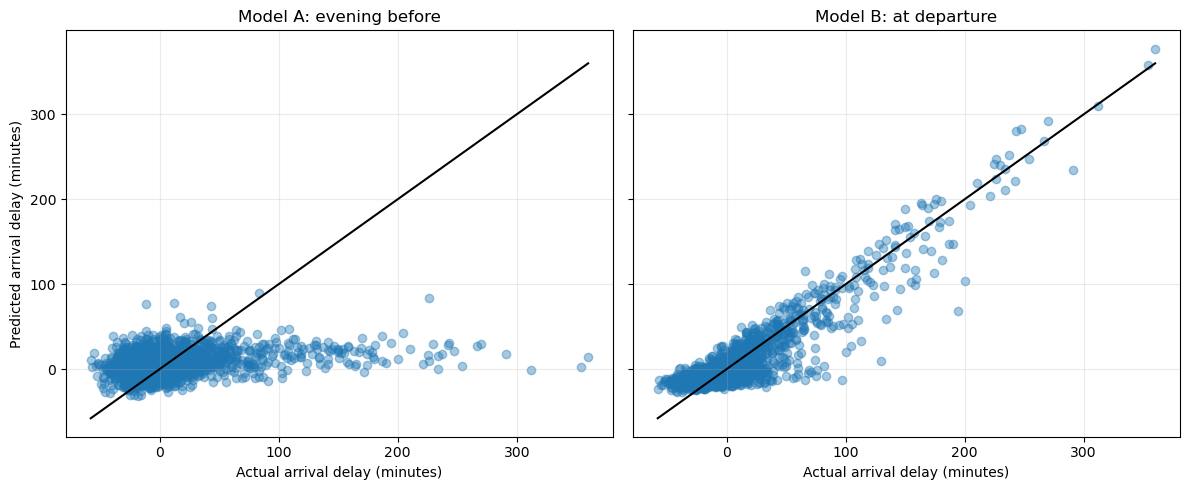

In [25]:
# Pick the same 2,000 random test flights for both panels
plot_rows = np.random.default_rng(42).choice(len(y_test), size=2000, replace=False)
actual = y_test.to_numpy()[plot_rows]

# One panel per model; the black line marks perfect predictions
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, pred, title in [
    (axes[0], pred_a[plot_rows], "Model A: evening before"),
    (axes[1], pred_b[plot_rows], "Model B: at departure"),
]:
    ax.scatter(actual, pred, alpha=0.4)
    low, high = actual.min(), actual.max()
    ax.plot([low, high], [low, high], color="black", linewidth=1.5)
    ax.set_title(title)
    ax.set_xlabel("Actual arrival delay (minutes)")
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel("Predicted arrival delay (minutes)")
plt.tight_layout()
plt.show()

*Plot description:* In the left panel (Model A), almost all predictions stay between about -20 and +50 minutes, even for flights that were several hours late, so the points form a flat cloud. In the right panel (Model B), the points lie close to the diagonal line, so the predictions follow the actual delays much more closely.

## 10. Prediction Timing, Data Leakage, and Explanation

**Prediction is not the same as explanation.**

- We are mainly learning the prediction workflow.
- Coefficients describe associations in this model. We should not claim that a feature causes delays.

**Timing decides which features are allowed.**

- Model B is much more accurate, but it can only be used **after** the plane leaves the gate. It cannot help with the staffing plan made the evening before.
- Using a feature that is not yet known at the decision time is called **data leakage**. A model with leakage can look very accurate in the notebook but fail in real use.
- Example: `air_time` (minutes in the air) is known only **after landing**. A model that uses it would look even better than Model B, but it would be useless for both decisions. You will measure this in the offline assignment.
- Even Model A uses observed weather as a stand-in for a forecast, so its real-world performance could be slightly worse.

A good business interpretation is clear about what the model can and cannot support.

## 11. Final Practice: Daily Bike Rental Demand

The flight models taught the workflow and the timing rule, but their results are either weak (Model A) or almost automatic (Model B: arrival delay is close to departure delay). Now you apply the **same workflow** to a problem where the features carry real business information.

**Business scenario.** A bike-sharing company in Washington, D.C. decides each evening how many bikes to move to busy stations and how many staff to schedule for **tomorrow**. At that time it knows tomorrow's calendar and has a weather forecast.

- **One row:** one day (2011-2012, 731 days)
- **Target:** `rentals`, the number of bikes rented that day
- **Features:** weather and calendar information known the evening before

Data: UCI Machine Learning Repository, *Bike Sharing* dataset (Fanaee-T, 2013), CC BY 4.0, based on Capital Bikeshare data. We converted the weather values to degrees Celsius, percent, and km/h and gave the categories readable names; `data/README_data.md` lists every change.

In [26]:
bike = pd.read_csv(repo_root / "data" / "bike_sharing_daily.csv")

# Put the categories in a natural order; the first one becomes the reference category
bike["season"] = pd.Categorical(bike["season"], categories=["winter", "spring", "summer", "fall"])
bike["weather"] = pd.Categorical(bike["weather"], categories=["clear", "mist_cloudy", "light_rain_snow"])

# 1 for days in 2012, 0 for days in 2011
bike["year_2012"] = (bike["year"] == 2012).astype(int)

print("Days:", len(bike), "| average rentals per day:", round(bike["rentals"].mean()))
bike.head()


Days: 731 | average rentals per day: 4504


,date,year,month,season,holiday,workingday,weather,temp_c,humidity_pct,windspeed_kmh,casual,registered,rentals,year_2012
0,2011-01-01,2011,1,winter,0,0,mist_cloudy,14.1,80.6,10.7,331,654,985,0
1,2011-01-02,2011,1,winter,0,0,mist_cloudy,14.9,69.6,16.7,131,670,801,0
2,2011-01-03,2011,1,winter,0,1,clear,8.1,43.7,16.6,120,1229,1349,0
3,2011-01-04,2011,1,winter,0,1,clear,8.2,59.0,10.7,108,1454,1562,0
4,2011-01-05,2011,1,winter,0,1,clear,9.3,43.7,12.5,82,1518,1600,0


### Which columns may we use?

- `casual` and `registered` count the two kinds of riders, and they **add up to `rentals`**. They are known only at the end of the day, so using them would be data leakage, just like `air_time` for flights. We do not use them.
- Every day is one of three types: a **weekend day**, a **holiday** (all holidays in this data fall on weekdays), or a **working day**. `holiday` and `workingday` are 0/1 columns, and the weekend day is the reference type they are compared with.
- `year_2012` is 1 for days in 2012 and 0 for days in 2011.
- `season` and `weather` become 0/1 dummy columns. Winter and clear weather are the reference categories.

**As with flights, the weather values are what was observed that day.** The evening before, the company would only have a forecast, so the model's results are a little optimistic.

The next cell builds `X_bike` and `y_bike` and makes the same kind of train/test split as before.

In [27]:
bike_features = ["temp_c", "humidity_pct", "windspeed_kmh", "holiday", "workingday", "year_2012", "season", "weather"]

# Dummy columns for season and weather
X_bike = pd.get_dummies(bike[bike_features], columns=["season", "weather"], drop_first=True, dtype=int)
y_bike = bike["rentals"]

# 75% training days, 25% test days
X_bike_train, X_bike_test, y_bike_train, y_bike_test = train_test_split(
    X_bike, y_bike, test_size=0.25, random_state=42
)

print("Training days:", len(X_bike_train), "| test days:", len(X_bike_test))
print("Columns:", list(X_bike.columns))


Training days: 548 | test days: 183
Columns: ['temp_c', 'humidity_pct', 'windspeed_kmh', 'holiday', 'workingday', 'year_2012', 'season_spring', 'season_summer', 'season_fall', 'weather_mist_cloudy', 'weather_light_rain_snow']


In [28]:
# Final Practice Step 1
# Create bike_model = LinearRegression() and fit it on X_bike_train and y_bike_train.

bike_model = LinearRegression()
bike_model.fit(X_bike_train, y_bike_train)

# Then predict the test days and name the result bike_pred.

bike_pred = bike_model.predict(X_bike_test)

In [29]:
# Final Practice Step 2
# Create bike_metrics, a DataFrame with two regression_metrics(...) rows on the test days:
#   1. "Baseline": the training average for every test day. Hint: np.full(len(y_bike_test), y_bike_train.mean())
#   2. "Bike demand model": bike_pred
# Use "evening before" as the decision time for both. Display bike_metrics.round(3), then save it:
#   bike_metrics.to_csv(output_dir / "bike_demand_metrics_module12.csv", index=False)

bike_baseline_pred = np.full(len(y_bike_test), y_bike_train.mean())
bike_metrics = pd.DataFrame([
    regression_metrics("Baseline", "evening before", y_bike_test, bike_baseline_pred),
    regression_metrics("Bike demand model", "evening before", y_bike_test, bike_pred),
])
print(bike_metrics.round(3))

bike_metrics.to_csv(output_dir / "bike_demand_metrics_module12.csv", index=False)
bike_metrics.round(3)

               model   decision_time       MAE      RMSE  R_squared
0           Baseline  evening before  1662.978  1983.325     -0.021
1  Bike demand model  evening before   586.952   773.488      0.845


,model,decision_time,MAE,RMSE,R_squared
0,Baseline,evening before,1662.978,1983.325,-0.021
1,Bike demand model,evening before,586.952,773.488,0.845


The next cell shows each coefficient with its unit. It works after you complete Step 1.

**Read season together with temperature.** Summer is the warmest season, so season and temperature overlap strongly. Each season coefficient compares seasons **at the same temperature**, so it can differ from the raw season averages (for example, the summer coefficient is smaller than the spring and fall coefficients, even though summer has the most rentals on average).

In [30]:
# Final Practice Step 3 (given): read the coefficients per unit
bike_units = {
    "temp_c": "1 degree Celsius warmer",
    "humidity_pct": "1 percentage point more humidity",
    "windspeed_kmh": "1 km/h more wind",
    "holiday": "a holiday (vs. a weekend day)",
    "workingday": "a working day (vs. a weekend day)",
    "year_2012": "a day in 2012 (vs. 2011)",
    "season_spring": "spring (vs. winter)",
    "season_summer": "summer (vs. winter)",
    "season_fall": "fall (vs. winter)",
    "weather_mist_cloudy": "mist or clouds (vs. clear)",
    "weather_light_rain_snow": "light rain or snow (vs. clear)",
}

# Show a reminder if Step 1 has not been run yet
if "bike_model" not in globals():
    print("Complete Final Practice Step 1 first, then run this cell again.")
else:
    bike_coefficients = pd.DataFrame({
        "feature": X_bike.columns,
        "change_in_predicted_rentals": bike_model.coef_.round(1),
        "per": [bike_units[col] for col in X_bike.columns],
    })
    display(bike_coefficients)


,feature,change_in_predicted_rentals,per
0,temp_c,127.4,1 degree Celsius warmer
1,humidity_pct,-11.0,1 percentage point more humidity
2,windspeed_kmh,-38.2,1 km/h more wind
3,holiday,-584.5,a holiday (vs. a weekend day)
4,workingday,147.4,a working day (vs. a weekend day)
5,year_2012,1995.1,a day in 2012 (vs. 2011)
6,season_spring,1193.4,spring (vs. winter)
7,season_summer,781.5,summer (vs. winter)
8,season_fall,1628.8,fall (vs. winter)
9,weather_mist_cloudy,-515.4,mist or clouds (vs. clear)


**Final Practice answer (5-6 sentences):** Write for the operations manager.

1. Compare the bike demand model with the baseline using MAE (in bikes per day) and R-squared.
2. Interpret three coefficients per unit in business language, for example temperature, light rain or snow, and `year`. Use cautious (non-causal) wording.
3. Explain in one sentence why this model explains demand so much better than flight Model A did. Hint: think about what one row means here and what drives the target.
4. State one limitation. Keep in mind: the random split mixes days from the whole two years, so each test day has training days from the same weeks (predicting a future month would be less accurate); the weather is observed, not forecast; and the `year_2012` coefficient reflects the growth of the system from 2011 to 2012 and should not be extended to later years.
5. Name one decision the company could support with this model.

Type your answer here.

1. The bike demand model preformed better than the basline, with an MAE of 586.952 compared to 1,662.978 bikes and an R-squared of 0.845 compared to -0.021.
2. The model suggests that a 1 degree celcius increase in temperature is associated with 127 more rentals, a 1% increase in humidity with 11 fewer rentals, and days in 2012 with 1,995 more rentals then 2011, assuming other factors stay the same.
3. The bike demand model performed better than flight Model A because weather and calendar information are more useful for predicting bike rentals then flight delays.
4. One limitation is that the model uses actual weather conditions instead of forecasts, which could make predictions less accurate when planning ahead.
5. he company could use this model to predict daily rentals and make better decisions about staffing and bike availability.

## 12. Offline Assignment - Prediction-Timing Comparison

The data science team proposes a third model, **Model C**, that adds `air_time` to the Model B features. They say it is "the most accurate model".

1. Add the `air_time` column to copies of `X_train` and `X_test`. Hint: `model_data.loc[X_train.index, "air_time"]` gives the air time for the training rows (do the same for `X_test.index`).
2. Fit Model C on the training data with all Model B columns plus `air_time`, and predict the test data.
3. Create `timing_comparison`, a DataFrame with one row each for Model A, Model B, and Model C. Use `regression_metrics()`, with `"after landing"` as the decision time for Model C.
4. Add a column `usable_evening_before` (Yes/No) and a column `usable_at_departure` (Yes/No).
5. Save `timing_comparison` as `outputs/linear_model_timing_comparison_module12.csv`.

The goal is not to make the "best" model win. The goal is to match each model's features to the time of the decision.

In [31]:
# Offline Assignment - your code here
# Suggested sequence:
# 1. X_train_c = X_train.copy(); X_train_c["air_time"] = model_data.loc[X_train.index, "air_time"]
#    (do the same for X_test_c)
# 2. landing_columns = departure_columns + ["air_time"]; fit model_c and create pred_c.
# 3. timing_comparison = pd.DataFrame([regression_metrics(...), ...]) for Models A, B, and C.
# 4. Add the usable_evening_before and usable_at_departure columns.
# 5. Save timing_comparison with output_dir / "linear_model_timing_comparison_module12.csv".

x_train_c = X_train.copy()
x_train_c["air_time"] = model_data.loc[X_train.index, "air_time"]
x_test_c = X_test.copy()
x_test_c["air_time"] = model_data.loc[X_test.index, "air_time"]
air_time_median = model_data["air_time"].median()
x_train_c["air_time"] = x_train_c["air_time"].fillna(air_time_median)
x_test_c["air_time"] = x_test_c["air_time"].fillna(air_time_median)
print("Missing values in X_train_c:", x_train_c.isna().sum().sum())

landing_columns = departure_columns + ["air_time"]
model_c = LinearRegression()
model_c.fit(x_train_c[landing_columns], y_train)
pred_c = model_c.predict(x_test_c[landing_columns])
print("Model C fitted and predictions made.")

timing_comparison = pd.DataFrame([
    regression_metrics("Model A", "evening before", y_test, pred_a),
    regression_metrics("Model B", "at departure", y_test, pred_b),
    regression_metrics("Model C", "at landing", y_test, pred_c),
])
print(timing_comparison.round(3))

timing_comparison["usable_evening_before"] = [True, True, False]
timing_comparison["usable_at_departure"] = [False, True, True]
timing_comparison["usable_at_landing"] = [False, False, True]
print(timing_comparison.round(3))

timing_comparison.to_csv(output_dir / "linear_model_timing_comparison_module12.csv", index=False)
timing_comparison.round(3)



Missing values in X_train_c: 0
Model C fitted and predictions made.
     model   decision_time     MAE    RMSE  R_squared
0  Model A  evening before  26.584  42.732      0.093
1  Model B    at departure  12.692  17.436      0.849
2  Model C      at landing  10.700  14.891      0.890
     model   decision_time     MAE    RMSE  R_squared  usable_evening_before  \
0  Model A  evening before  26.584  42.732      0.093                   True   
1  Model B    at departure  12.692  17.436      0.849                   True   
2  Model C      at landing  10.700  14.891      0.890                  False   

   usable_at_departure  usable_at_landing  
0                False              False  
1                 True              False  
2                 True               True  


,model,decision_time,MAE,RMSE,R_squared,usable_evening_before,usable_at_departure,usable_at_landing
0,Model A,evening before,26.584,42.732,0.093,True,False,False
1,Model B,at departure,12.692,17.436,0.849,True,True,False
2,Model C,at landing,10.700,14.891,0.890,False,True,True


### Deployment Recommendation

**Your response here:** Write 5-6 sentences for the operations manager. Compare Models A, B, and C with metric evidence (MAE in minutes and R-squared). Explain why Model C should not be used even though it has the best metrics. Recommend which model fits the evening-before staffing plan and which fits the at-departure arrival update. State one limitation (for example, observed weather instead of a forecast) and avoid claiming that the features cause arrival delay.

- Model A had an MAE of 26.584 minutes and an r-squared of 0.093, making it the meast accurate of the 3 models.
- Model B performed much better, with an MAE of 12.692 minutes and an r-squared of 0.849.
- Model C was the most accurate with an MAE of 10.700 minutes and an r-squared of 0.890.
-Even though Model C performed the best, it should not be used for advance predictions because actual air time is not available until after landing.
- I would recommend Model A for evening-before staffing decisions and Model B for updating arrival predictions at departure. 
- One limitation is that the models use actual weather conditions instead of forecasts, which could make predictions less accurate when used in real-worl situations. 

## 13. Final Reflection

Write 5-7 sentences answering:

1. What was the target variable, and what does one row represent?
2. How did the decision time change which features you could use?
3. What does the train/test split help us do?
4. Which metric was easiest to interpret, and why?
5. What is one limitation of these models?
6. How might you apply this workflow (including a baseline and a timing check) to your project ABT?

**Your reflection:**
1. the target variable was arrival delay in minutes, and each row represented one flight.
2. The decision time determined which features could be used because some information was not avaible until departure or landing. 
3. The train test split allowed us to train the models on 1 set of data and test their accuracy on data they had not seen before.
4. MAE was the easiest to interpret because it showed the average prediction error in minutes.
5. 1 limitation is that the models used actual weather conditions instead of forecasts, whcih could make real-worl predictions less accurate.
6. I could apply this workflow to my movie project ABT by comparing a baseline with my prediction model and making sure the features were available before the movie's performance was known.

## 14. Save Your Work

Week 12 and Week 13 use the same repository. **Week 12 is graded on the Module 12 deadline from this module12 notebook and its three Module 12 output files.** Week 13 is graded later from the module13 notebook.

Before the Module 12 deadline:

1. Complete all Your Turn, Final Practice, and Offline Assignment sections.
2. Complete the deployment recommendation and final reflection.
3. Restart the kernel and run all cells from top to bottom.
4. Confirm all three Module 12 CSV files exist in `outputs`:
   - `linear_regression_metrics_module12.csv`
   - `bike_demand_metrics_module12.csv`
   - `linear_model_timing_comparison_module12.csv`
5. Save the notebook, then commit and push your work.

```bash
git add .
git commit -m "Complete Module 12 linear regression lab"
git push
```